In [1]:
import numpy as np
import pandas as pd
import glob
import scipy 
from tqdm import tqdm 
import anndata
import scanpy as sc 
import os

In [2]:
donorID = 'H20.33.001'
detect_transcript_fls  = glob.glob(rf'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/SEA_AD_dataset/{donorID}/*/*.csv')
detect_transcript = []
for fl in detect_transcript_fls:
    barcode = fl.split(os.sep)[-2]
    df = pd.read_csv(fl, index_col=0)
    df['Specimen Barcode'] = barcode
    detect_transcript.append(df)
detect_transcript = pd.concat(detect_transcript,axis=0)
detect_transcript

,barcode_id,global_x,global_y,global_z,x,y,fov,gene,transcript_id,cell_id,Specimen Barcode
Unnamed: 0,,,,,,,,,,,
28347,2,83.431610,8824.224609,0.0,967.684937,176.461472,2,RORB,ENST00000376896,1117162534103780055,1194111462
29250,2,88.038597,8887.081055,0.0,1010.342163,758.461487,2,RORB,ENST00000376896,-1,1194111462
30198,2,181.827454,8955.339844,0.0,1878.757446,1390.487915,2,RORB,ENST00000376896,1117162534103780088,1194111462
30815,2,154.052704,8677.735352,0.0,1636.313965,685.095886,3,RORB,ENST00000376896,-1,1194111462
30982,2,155.960815,8692.422852,0.0,1653.981567,821.086365,3,RORB,ENST00000376896,1117162534103570172,1194111462
...,...,...,...,...,...,...,...,...,...,...,...
2514661,149,9619.026367,5320.336426,6.0,169.058838,1110.373413,2095,Blank-9,-1,-1,1217500590
2534389,149,9723.407227,4717.023926,6.0,1135.555664,1080.145508,2098,Blank-9,-1,1206221615102530421,1217500590
2534951,149,9733.125977,4178.457031,6.0,1225.539429,1649.417358,2101,Blank-9,-1,1206221615102270357,1217500590


In [3]:
# load the anndata object 
adata = anndata.read_h5ad(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/SEA_AD_dataset/combined_anndata_object/SEAAD_MTG_MERFISH.2024-12-11.h5ad')

- Normalize the expression matrix. 

In [4]:
# log1p normalize the count matrix 
adata.layers['X_raw'] = adata.X.copy()
total_count = adata.X.sum(axis=-1)
sc.pp.normalize_total(adata, target_sum = np.median(total_count))
sc.pp.log1p(adata)
adata.layers['log1p_count'] = adata.X.copy()

#### New cell

In [5]:
np.unique(adata.obs['Subclass'])

array(['Astrocyte', 'Chandelier', 'Endothelial', 'L2/3 IT', 'L4 IT',
       'L5 ET', 'L5 IT', 'L5/6 NP', 'L6 CT', 'L6 IT', 'L6 IT Car3', 'L6b',
       'Lamp5', 'Lamp5 Lhx6', 'Microglia-PVM', 'OPC', 'Oligodendrocyte',
       'Pax6', 'Pvalb', 'Sncg', 'Sst', 'Sst Chodl', 'VLMC', 'Vip'],
      dtype=object)

In [6]:
from tqdm import tqdm 
SAVE_ROOT_PATH = r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/analysis_result'
celltype_list = ['Sst','Pvalb','Sst Chodl','L2/3 IT','L5 IT']
all_genes = np.asarray(adata.var_names)
keep_donor = adata.obs['Donor ID'] == donorID
specimen_barcode = list(set(adata[keep_donor].obs['Specimen Barcode']))
for specimen_ in specimen_barcode:
    keep_sample = adata.obs['Specimen Barcode'] == specimen_
    subadata = adata[keep_donor & keep_sample].copy()
    for e1 in celltype_list:
        # get the mean experssion across all cell-types 
        mean_all = np.mean(subadata[:,all_genes].X,axis=0)
        meanDH = np.mean(subadata[:,all_genes][subadata.obs['Subclass'] == e1].X,axis=0) - mean_all

        # Get cells that show the mean gene expression 
        iindex = np.where(subadata.obs['Subclass'] == e1)[0]
        best_cor = np.argsort([np.corrcoef(meanDH,e)[0,1]  for e in subadata.X[iindex] - mean_all])[::-1]
        ibest_cells = subadata.obs['Cell ID'][iindex[best_cor]].values # cell-ids sorted based on correlation 
        # loop through at most top 500 cells.
        NUM_CELLS = np.minimum(100,len(iindex))

        for icellSEL in tqdm(ibest_cells[:NUM_CELLS], desc = f'{e1}:transcript density clustering'):
            SAVE_PATH = SAVE_ROOT_PATH + os.sep  + 'density_based_clustering' + os.sep + donorID + os.sep + specimen_ + os.sep + f'{e1}_{icellSEL}.npz'
            os.makedirs(os.path.dirname(SAVE_PATH),exist_ok = True) # create the required folder 
            # identify the fov within which the cells are located and restrict the detected transcripts to the FOV
            keep_transcripts = (detect_transcript['cell_id'] == icellSEL) & (detect_transcript['Specimen Barcode'] == specimen_)
            fov = detect_transcript.loc[keep_transcripts,'fov'].unique()
            # subset the transcript csv to transcripts within FOV for that specific donor and specimen barcode 
            keep_transcripts = (detect_transcript['fov'].isin(fov)) & (detect_transcript['Specimen Barcode'] == specimen_)
            fov_detected_transcript = detect_transcript.loc[keep_transcripts]

            # ID assigned to cells 
            icell = fov_detected_transcript['cell_id'].values
            genes = fov_detected_transcript['gene'].values

            # count the number of genes assigned to teh selected cells assigned within the fov
            gns_,cts = np.unique(genes[icell == int(icellSEL)], return_counts = True)
            dict_cts = dict(zip(gns_,cts/np.sum(cts)))

            # count ambient transcripts, transcripts not assigned to any cell (i.e. non-soma RNA)
            gns_,cts = np.unique(genes[icell == -1],return_counts = True)
            dict_cts_bk = dict(zip(gns_,cts/np.sum(cts)))
            # calculate teh enrichment of each genes, i.e. fold change with respect to the non-soma transcripts
            enrich = np.array([dict_cts[gn]/(dict_cts_bk.get(gn,0) + 1e-11) for gn in dict_cts])
            # keep only genes that show foldchange greater than 3 
            gns_kp = np.asarray(list(dict_cts.keys()))[enrich > 3]
            # also make sure the mean expression is greater than 0 
            gns_kp = np.intersect1d(gns_kp,all_genes[meanDH > 0])
            kp = np.isin(genes,gns_kp)
            # the spatial XYZ postion of the transcript spots
            Xall = fov_detected_transcript[['global_x','global_y','global_z']].values  * [1,1,1.5]# this is already in microns.
                                                                                                  # except for the z-location
            
            Xall_kp_df = fov_detected_transcript[kp]
            Xall_kp = Xall[kp]
            X_cell_kp = Xall[(icell==int(icellSEL)) & kp]

            # Find the nearest neighbor to each soma transcript of the selected cell 
            N = 5
            dd,ii = scipy.spatial.KDTree(X_cell_kp).query(X_cell_kp,N)
            dth = np.median(dd[:,-1]) # median distance of each trancript from the other transcript 

            # find the nearest neighbor to each non-soma transcript 
            X_bk = Xall[(icell == -1) & kp]
            dd,ii = scipy.spatial.KDTree(X_bk).query(X_bk,N)
            dth_bk = np.median(dd[:,-1])

            try:
                # cluster the transcript based on their density 
                from sklearn.cluster import DBSCAN
                dbscan = DBSCAN(eps = (dth + dth_bk)/2, min_samples = N)
                lab = dbscan.fit(Xall_kp).labels_
            except:
                print(f'Failed at - {e1}:{icellSEL}')
                continue 
            # get the number of genes with in each DBSCAN cluster label that is associated within the selected cell
            ulab = np.unique(lab)
            mean_cell = [np.mean(icell[kp][lab==ilab] == int(icellSEL)) for ilab in ulab]
            best = ulab[np.argmax(mean_cell)] # get the DBSCAN cluster label that contains most of the transcript 
            # get the DBSCAN cluster label that contains most of the transcript using KDTree
            dd,ii = scipy.spatial.KDTree(Xall_kp).query(X_cell_kp)
            bd,cts = np.unique(lab[ii], return_counts = True)
            best = bd[np.argmax(cts)]

            X = Xall_kp[best==lab] # get all the transcripts with the most dense DBSCAN cluster, 
                                   # which is most likly the **soma transcripts**
                                   # NOTE: this is based on transcript enriched in the soma. 
            Xall_kp_df = Xall_kp_df[best==lab]

            # include using all transcripts 
            dd,ii = scipy.spatial.KDTree(X).query(Xall)
            kpf  = dd<2
            Xall = Xall[kpf,:]
            genes_all = genes[kpf]
            Xall_df = fov_detected_transcript[kpf]
            # save the result 
            np.savez_compressed(
                                SAVE_PATH,
                                X_somatic = X, # segmetnation based on somatic genes 
                                genes_somatic_enr = genes[kp], # somatic enriched genes
                                X_df = Xall_kp_df,  # transcript df
                                Xall = Xall, # segmentation based on all genes 
                                genes_all = genes_all, # all genes 
                                Xall_df = Xall_df,
                                pix_size = [1,1,1.5],

                                allow_pickle = True
                                )

    break
            





/tmp/ipykernel_3145347/3820721871.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ibest_cells = subadata.obs['Cell ID'][iindex[best_cor]].values # cell-ids sorted based on correlation
Sst:transcript density clustering: 100%|██████████| 100/100 [05:01<00:00,  3.01s/it]
/tmp/ipykernel_3145347/3820721871.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ibest_cells = subadata.obs['Cell ID'][iindex[best_cor]].values # cell-ids sorted based on correlation
Pvalb:transcript density clustering: 100%|██████████| 100/100 [05:02<00:00,  3.02s/it]
/tmp/ipykernel_3145347/3820721871.py:18: FutureWarning: Series.__getitem__

#### Visualize the result in 3D matplotlib. 

In [36]:
import matplotlib.pyplot as plt
import scipy 
def add_scale_bar_3d(ax, length=5, color='k', lw=1, fontsize=6):
    """Draw a 3-arm scale bar at the lower corner. Each arm = `length` data units (µm)."""
    ax.autoscale(False)  # stop the bar from changing the axis limits
    x0, y0, z0 = ax.get_xlim()[0], ax.get_ylim()[0], ax.get_zlim()[0]
    for dx, dy, dz in [(length, 0, 0), (0, length, 0), (0, 0, length)]:
        ax.plot([x0, x0 + dx], [y0, y0 + dy], [z0, z0 + dz], color=color, lw=lw)
    ax.text(x0, y0, z0 - 0.08 * np.ptp(ax.get_zlim()), f'{length} µm',
            color=color, fontsize=fontsize, ha='center', va='top')


fls = glob.glob(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/analysis_result/density_based_clustering/H20.33.001/1217500585/*.npz')
for fl in fls: 
    val = np.load(fl,allow_pickle=True)
    X_somatic = val['X_somatic']
    X_all = val['Xall']
    fig = plt.figure(dpi = 300,figsize = (3,4))
    ax = fig.add_subplot(projection = '3d')
    # ax.scatter(X_somatic[:,1],X_somatic[:,2],X_somatic[:,0], fc = 'b',ec = 'b', s = 2)
    ax.scatter(X_all[:,1],X_all[:,2],X_all[:,0], fc = 'r',ec = 'r', s = 2)
    ax.set_aspect('equal')      # needed: makes 1 µm the same length on all axes
    ax.set_proj_type('ortho')   # needed: removes perspective, so length doesn't change with depth
    ax.grid(False)
    ax.set_axis_off()
    add_scale_bar_3d(ax, length=5)
    plt.savefig(fl.replace('.npz','.png'), bbox_inches = 'tight')
    plt.show()
    plt.close()

In [33]:
specimen_

'1217500585'

In [ ]:
# sst: Sst_1210003121101840246, Sst_1210003121103700140, Sst_1210003121101560295

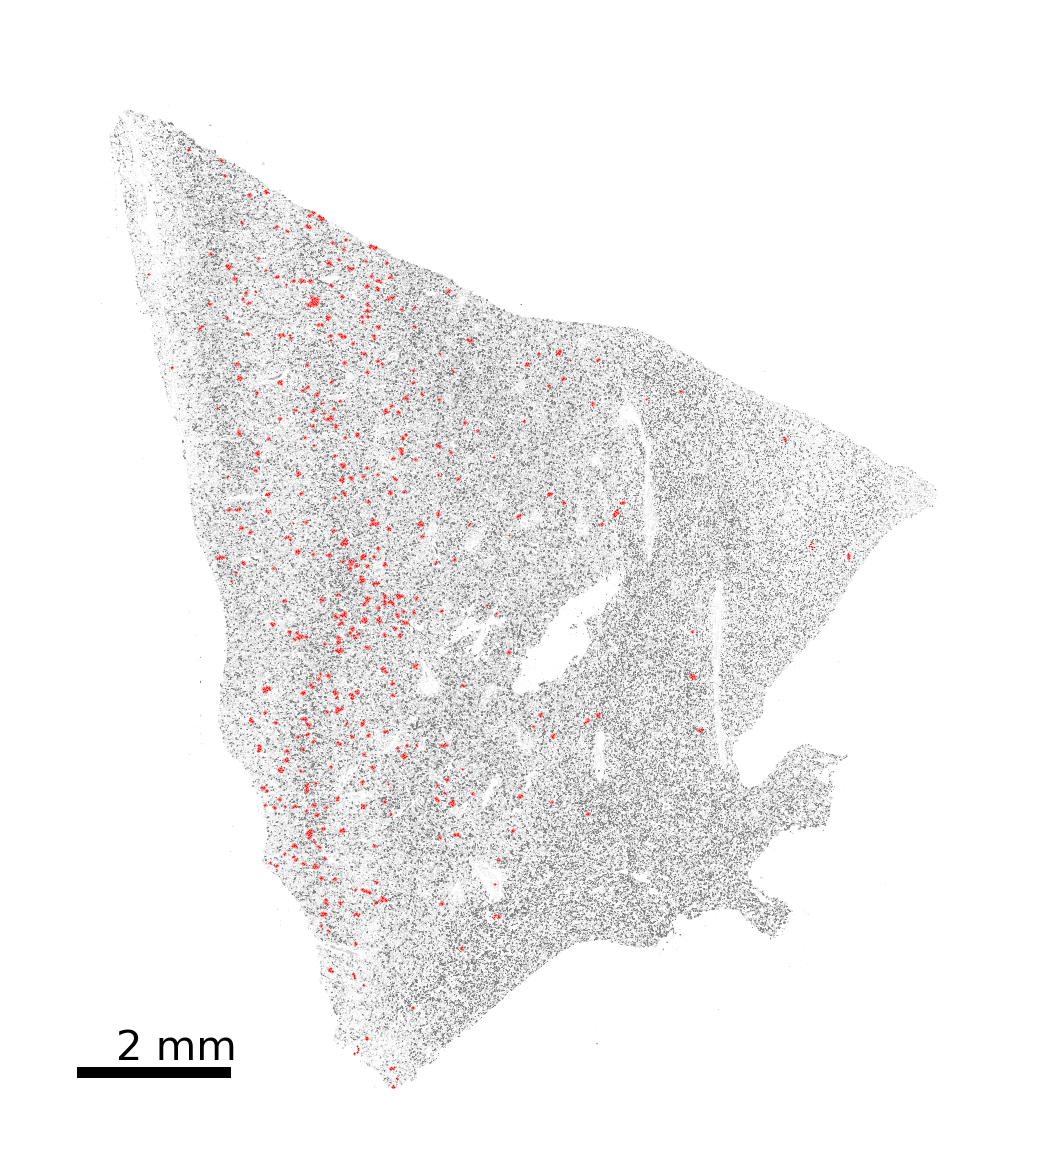

In [35]:
# spatial distribution of transcripts 
import matplotlib.patches as patches
import matplotlib.pyplot as plt 
import seaborn as sns 
fls = glob.glob(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/analysis_result/density_based_clustering/H20.33.001/1217500585/*.npz')
specimen_ = specimen_barcode[0]
keep_sample = detect_transcript['Specimen Barcode'] == specimen_

fig,ax = plt.subplots(1,1,dpi = 300)
sns.scatterplot(detect_transcript[keep_sample],x ='global_x' , y ='global_y' , ax = ax, s = 0.001, c = 'gray')
# plot the sampled transcripts 
for fl in fls: 
    val = np.load(fl,allow_pickle=True)
    # X_somatic = val['X_somatic']
    # X_all = val['Xall']
    df = pd.DataFrame(val['Xall_df'],columns = detect_transcript.columns)
    sns.scatterplot(df[df['Specimen Barcode'] == specimen_],x ='global_x' , y ='global_y' , s = 0.1, c ='red')
rec = patches.Rectangle([0,0],2000,150, fc = 'k')
ax.add_patch(rec)
ax.text(500,250,'2 mm')
ax.set_aspect('equal')
ax.set_axis_off()

plt.show()